<a href="https://colab.research.google.com/github/alimoorreza/CS181-fall26-notes/blob/main/day20_generative_model_VAE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import torch
import numpy as np
import torch.nn as nn
from torch.optim import Adam
import torchvision.transforms as transforms
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
from torchvision.utils import save_image, make_grid

In [ ]:
# download the MNIST datasets
path = '/content/drive/MyDrive/cs181_fall26/module_7_generative_model_vae/dataset/'
#path = '/content/'

#transform     = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()]) # create a transofrm to apply to each datapoint
transform     = transforms.Compose([transforms.ToTensor()]) # create a transofrm to apply to each datapoint
train_dataset = MNIST(path, transform=transform, download=True)
test_dataset  = MNIST(path, transform=transform, download=True)

In [ ]:
# create train and test dataloaders
batch_size    = 100
train_loader  = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader   = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)
device        = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
dataiter      = iter(train_loader)
image         = next(dataiter)
#print(image[0].shape)     # index-0 has the image contents for the entire batch
print('labels: ', image[1]) # index-1 has the labels for the entire batch

labels:  tensor([9, 4, 3, 6, 4, 6, 2, 8, 3, 2, 9, 0, 7, 3, 4, 0, 9, 8, 7, 1, 5, 8, 8, 8,
        5, 0, 6, 2, 7, 2, 3, 9, 2, 6, 2, 0, 9, 1, 6, 0, 2, 6, 0, 8, 7, 6, 2, 3,
        4, 3, 3, 1, 0, 9, 8, 7, 6, 0, 9, 7, 0, 1, 4, 3, 2, 6, 7, 7, 3, 6, 5, 7,
        2, 5, 9, 9, 2, 3, 6, 6, 4, 4, 6, 9, 0, 3, 7, 0, 7, 6, 0, 6, 2, 9, 8, 2,
        7, 3, 3, 7])


labels:  [1, 9, 7, 1, 3, 6, 2, 1, 7, 4, 2, 9, 3, 5, 9, 4, 2, 2, 0, 6, 1, 9, 9, 6, 7, 7, 8, 8, 9, 4, 8, 8, 0, 8, 2, 7, 9, 3, 0, 3, 1, 7, 8, 8, 9, 3, 9, 1, 5, 4, 4, 3, 8, 9, 8, 5, 4, 0, 0, 2, 7, 1, 1, 9, 5, 3, 2, 0, 9, 2, 6, 6, 3, 2, 3, 0, 6, 7, 5, 6, 4, 7, 8, 8, 2, 7, 0, 1, 8, 3, 5, 4, 9, 9, 6, 8, 9, 9, 4, 2]


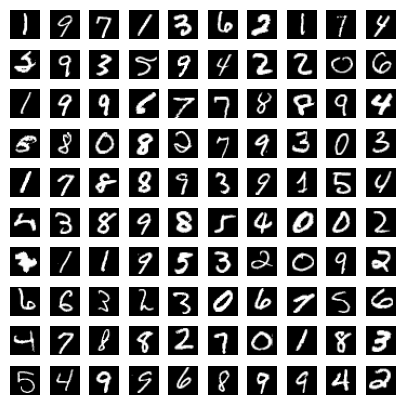

In [ ]:
# get 100 sample training images for visualization
dataiter      = iter(train_loader)
image         = next(dataiter)

num_samples   = 100
sample_images = [image[0][i,0] for i in range(num_samples)]
sample_labels = [int(image[1][i]) for i in range(num_samples)]
print('labels: ', sample_labels)

fig = plt.figure(figsize=(5, 5))
grid = ImageGrid(fig, 111, nrows_ncols=(10, 10), axes_pad=0.1)

for ax, im in zip(grid, sample_images):
    ax.imshow(im, cmap='gray')
    ax.axis('off')

plt.show()

In [ ]:
def loss_function(x, x_hat, mean, log_var):

    reproduction_loss = nn.functional.binary_cross_entropy(x_hat, x, reduction='sum')
    KLD               = - 0.5 * torch.sum(1+ log_var - mean.pow(2) - log_var.exp())

    return reproduction_loss + KLD

# generating a new sample using the trained VAE model
def generate_digit(mean, var, model):
    z_sample = torch.tensor([[mean, var]], dtype=torch.float).to(device)
    x_decoded = model.decode(z_sample)
    digit = x_decoded.detach().cpu().reshape(28, 28) # reshape vector to 2d array
    #digit = x_decoded.detach().cpu().reshape(32, 32) # reshape vector to 2d array
    plt.figure(figsize=(2, 2))
    plt.title(f'[{mean},{var}]')
    plt.imshow(digit, cmap='gray')
    plt.axis('off')
    plt.show()



In [ ]:
class VAE(nn.Module):

    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=200, device=device):
        super(VAE, self).__init__()

        # encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, latent_dim),
            nn.LeakyReLU(0.2)
            )

        # latent mean and variance
        self.mean_layer   = nn.Linear(latent_dim, 2)
        self.logvar_layer = nn.Linear(latent_dim, 2)

        # decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, latent_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(latent_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
            )

    def encode(self, x):
        x = self.encoder(x)
        mean, logvar = self.mean_layer(x), self.logvar_layer(x)
        return mean, logvar

    def reparameterization(self, mean, var):
        epsilon = torch.randn_like(var).to(device)
        z = mean + var*epsilon
        return z

    def decode(self, x):
        return self.decoder(x)

    def forward(self, x):
        mean, log_var = self.encode(x)
        z = self.reparameterization(mean, torch.exp(0.5 * log_var))
        x_hat = self.decode(z)
        return x_hat, mean, log_var


def train(model, optimizer, epochs, device, x_dim=784):
    model.train()
    for epoch in range(epochs):
        overall_loss = 0
        for batch_idx, (x, _) in enumerate(train_loader):
            x = x.view(batch_size, x_dim).to(device)

            optimizer.zero_grad()

            #import pdb
            #pdb.set_trace()

            x_hat, mean, log_var = model(x)
            loss = loss_function(x, x_hat, mean, log_var)

            overall_loss += loss.item()

            loss.backward()
            optimizer.step()

        print(f"Epoch {epoch} loss: {overall_loss/(batch_idx*batch_size)}")
    return overall_loss




###__Group Activity#1: MLP based VAE__
Finish the following tasks:
- train the model
- generate new digit image using the trained model

In [ ]:
# create MLP based VAE
model     = VAE().to(device)
optimizer = Adam(model.parameters(), lr=1e-3)
train(model, optimizer, epochs=50, device=device)

Epoch 0 loss: 179.38520409993217
Epoch 1 loss: 162.07688911858307
Epoch 2 loss: 157.39771709359349
Epoch 3 loss: 154.6840361540067
Epoch 4 loss: 152.89877220497704
Epoch 5 loss: 151.42564068369157
Epoch 6 loss: 150.32871395359453
Epoch 7 loss: 149.38895941477983
Epoch 8 loss: 148.57110216245826
Epoch 9 loss: 147.95072757982052
Epoch 10 loss: 147.38508190734558
Epoch 11 loss: 146.85825038801647
Epoch 12 loss: 146.39447846019408
Epoch 13 loss: 145.98056575412144
Epoch 14 loss: 145.60915790640652
Epoch 15 loss: 145.2734375
Epoch 16 loss: 145.01932993791735
Epoch 17 loss: 144.5684428637573
Epoch 18 loss: 144.5371009136321
Epoch 19 loss: 144.1976442182283
Epoch 20 loss: 143.94214775276504
Epoch 21 loss: 143.7234382173414
Epoch 22 loss: 143.44995169357784
Epoch 23 loss: 143.2071341232784
Epoch 24 loss: 143.0489763701221
Epoch 25 loss: 142.8779470667258
Epoch 26 loss: 142.61830003130217
Epoch 27 loss: 142.52516895020347
Epoch 28 loss: 142.2282044292571
Epoch 29 loss: 142.23196589041632
Epoch 

8376688.158203125

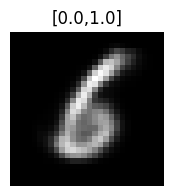

In [ ]:
# inference: random sample generation using mean and variance
generate_digit(0.0, 1.0, model) # mean=0 var=1.0

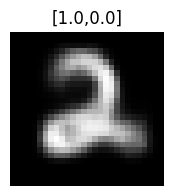

In [ ]:
# inference: random sample generation using mean and variance
generate_digit(1.0, 0.0, model) # mean=1.0, var=0.0

In [ ]:
# inference: random sample generation using a collection of means and variances
def plot_latent_space(model, scale=5.0, n=10, digit_size=28, figsize=10):

    # display a n*n 2D manifold of digits
    figure = np.zeros((digit_size * n, digit_size * n))

    # construct a grid
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    counter = 1
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            print(f"{counter}) Generating a new sample digits using mean={xi:.2f} and var={yi:.2f}")
            z_sample = torch.tensor([[xi, yi]], dtype=torch.float).to(device)
            x_decoded = model.decode(z_sample)
            digit = x_decoded[0].detach().cpu().reshape(digit_size, digit_size)
            figure[i * digit_size : (i + 1) * digit_size, j * digit_size : (j + 1) * digit_size,] = digit
            counter = counter + 1

    plt.figure(figsize=(figsize, figsize))
    plt.title('VAE Latent Space Visualization')
    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)
    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("mean, z [0]")
    plt.ylabel("var, z [1]")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

In [ ]:
plot_latent_space(model, scale=1.0, n=10)

In [ ]:
plot_latent_space(model, scale=5.0, n=10)